<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE SAMPLE TIME HAS CHANGED</h2>
<p style="margin:4px 0;"><b>The phonon sample period is 0.8 &micro;s (1.25 MHz), not 1.6 &micro;s (625 kHz).</b> A 4096-sample trace is 3.2768 ms. Until 2026-10-22 this notebook used 1.6 &micro;s, which was wrong.</p>
<p style="margin:4px 0;">What this means: times and energies are <b>half</b> of what older versions showed, frequencies are <b>doubled</b> (the axis now reaches 625 kHz), PSDs are halved and ASDs are divided by 1.41. Anything counted in samples or counts (cuts, selections, pulse heights) is unchanged.</p>
<p style="margin:4px 0;">This notebook was re-run with the new value (the library default, <code>PulseConfig</code> without <code>sample_period_s</code>). See <i>The sample period</i> in <code>python/README.md</code>.</p>
</div>

<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE CHANNEL MAP HAS CHANGED</h2>
<p style="margin:4px 0;"><b>This notebook used the wrong table columns for the channel names.</b> The series is read out on <b>Side 2</b>, so the right columns of the Run 76 Setup table are <i>Label</i> and <i>HV output, Side 2 readout</i> (not <i>DCRC (2-sided)</i>). There are <b>six sensors, all on Side 2</b>: DCRC1 pA, pB, pD = <code>Side2pC</code>, <code>Side2pF</code>, <code>Side2pE</code>; DCRC3 pA, pB, pD = <code>Side2pB</code>, <code>Side2pA</code>, <code>Side2pD</code>. DCRC4 pA is the <b>NaI trigger input</b> (not a phonon sensor) and the other five inputs are not connected. See <code>python/pulse_channels.py</code> (since 2026-10-22).</p>
<p style="margin:4px 0;">Names of the dump channels that changed: (0, 3) <code>Side1pF</code> is now <code>Side2pE</code>, (1, 0) <code>Side1pE</code> is <code>Side2pB</code>, (1, 1) <code>Side1pB</code> is <code>Side2pA</code>, (1, 3) <code>Side2pE</code> is <code>Side2pD</code>, (2, 0) <code>Side2pB</code> is the NaI input. (0, 0) <code>Side2pC</code> and (0, 1) <code>Side2pF</code> are as before. Everything keyed by (detector, channel) is unchanged.</p>
<p style="margin:4px 0;"><b>What changed in this notebook:</b></p>
<ul style="margin:4px 0;">
<li>The cut channel (1, 1) is now <code>Side2pA</code> (DCRC3 pB), the old <code>Side1pB</code>; the 101 events are the same.</li>
<li>The spectra are of the <b>six sensors</b> only (<code>Side2pC</code>, <code>Side2pF</code>, <code>Side2pE</code>, <code>Side2pB</code>, <code>Side2pA</code>, <code>Side2pD</code>). The NaI trigger input (DCRC4 pA, the old <code>Side2pB</code>) has no spectrum any more; the HDF5 file now has six channel groups with these names, <code>side</code> = 2, and the attributes <code>board_input</code> and <code>hv_output</code>. Any analysis that used the old group names must be redone.</li>
<li>The by-side figure is now by board (<code>psd-clean-randoms-by-board-*.png</code>: DCRC1 left, DCRC3 right); the tiles are coloured by board and the inputs that are not sensors are labelled.</li>
<li>Numbers that changed: the strictest cut is 34 events (31) and the 101-to-34 ratios are 0.98 to 1.21 (they were 0.97 to 1.08); the ASD of each channel is the same as before under its new name (for example <code>Side2pA</code> is the old <code>Side1pB</code>: 1.98e-3 above 100 kHz, 1.10e-2 at 1 to 10 kHz).</li>
</ul>
</div>

# Noise PSDs from the `clean_randoms` cut: series 07221203_2025, dump F0001

The cut developed in the note is the cut of Notes 2 and 2a made on `Side2pA` (Detector 1 / Channel 1, DCRC3): a random trigger in the Tight excursion band of a 500-sample pretrigger window with `log10(bstd) < 0.5`. It keeps 101 of the 1008 randoms, none of which has a pulse or a big tail in any channel (section 10 and 11 of `chan0-cut-on-all-channels-buddy.ipynb`, where the cut is defined as `clean_randoms`).

This notebook uses those same 101 events, **the same events for every channel**, to compute the noise spectrum of each of the six sensor channels, as a one-sided power spectral density (PSD, counts$^2$/Hz) and as the **amplitude spectral density** (ASD, its square root, in counts/$\sqrt{\mathrm{Hz}}$), which is what the figures show. The six inputs that are not sensors (the NaI trigger input and five unconnected inputs) have no spectrum and are skipped.

The PSD is the one-sided estimate of the note: for a baseline-subtracted trace of N samples taken every Δt, with Fourier transform X[k],

    S[k] = (2 Δt / N) · mean over the traces of |X[k]|²        (counts² / Hz)

with the factor 2 left out for the zero-frequency and Nyquist bins.

**Caveats.** `pulse_cuts.randoms` assumes the dump's trigger-type labels are swapped (Note 2a); and the channel names are provisional (`pulse_channels`: Side-2 readout, six sensors, DCRC1 A/B order from the table). Run with the `darkmatter_cli_env` kernel.

*Author: buddy. Draft.*


In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
import pulse_channels as pch
from pulse_config import PulseConfig

SENSORS = [(c.detector, c.channel) for c in pch.sensor_channels()]     # the six sensors of the Side-2 readout
BOARD_COLOUR = {"DCRC1": "#d95f02", "DCRC3": "#1f77b4"}               # orange: DCRC1 (Side2pC, pF, pE); blue: DCRC3 (Side2pB, pA, pD)

def inactive_text(c):
    """What to write in the tile of an input that is not a sensor."""
    if c.role == pch.NAI_TRIGGER:
        return "NaI trigger input" + chr(10) + "(not a phonon sensor)"
    return "not connected"

import check_environment
check_environment.check()

def short_label(det, ch):
    """Channel name with its readout board, e.g. 'Side2pC (DCRC1)'."""
    return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:20: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  SENSORS = [(c.detector, c.channel) for c in pch.sensor_channels()]     # the six sensors of the Side-2 readout


## 1. Load the dump and apply the cut

`clean_randoms_cut` is the cut of the note, written once. It is evaluated on `Side2pA` only, and the resulting event list is used for every channel.

In [2]:
DUMP = "07221203_2025_F0001"
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]

# The three boards share their events, in the same order, so one event list serves every channel.
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])
for det in (1, 2):
    assert np.array_equal(event_numbers, [int(pio.event_id(i)) for i in det_ids[det]])

CLEAN_KEY = (1, 1)        # Side2pA (DCRC3), the channel the cut is made on

def clean_randoms_cut(pulses, trigger_types, config=config_500):
    """Randoms with no pulse: the Note 2 / 2a cut (Tight excursion band and log10(bstd) < 0.5) on one channel."""
    with np.errstate(all="ignore"):
        quiet = pc.excursion_band(pulses, config) & (np.log10(pq.bstd(pulses, config)) < 0.5)
    return pc.randoms(trigger_types) & quiet

_, p_clean = pio.load_channel_batch(cdms, det_ids[CLEAN_KEY[0]], CLEAN_KEY[1])
clean_randoms = clean_randoms_cut(p_clean, pio.trigger_types(cdms, det_ids[CLEAN_KEY[0]]))   # <- the cut of the note
print(f"{len(event_numbers)} events; clean_randoms on {short_label(*CLEAN_KEY)}: {clean_randoms.sum()} events")

1517 events; clean_randoms on Side2pA (DCRC3): 101 events


C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\47365755.py:18: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  return pc.randoms(trigger_types) & quiet
C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\Research\NSDF-Data-buddy2\python\pulse_channels.py:129: UserWarning: channel_info is marked under_devel

## 2. One-sided PSD of every channel

Each trace is baseline-subtracted (the mean of the 500-sample pretrigger window, skipping the first 10 samples) and the 10 leading glitch samples are dropped, then Fourier transformed. A channel is **dead** if its traces never change (zero scatter in every trace).

In [3]:
def processed(pulse_array):
    # baseline-subtract (500-sample window) and drop the leading glitch samples
    return po.trim_glitch(po.baseline_subtract(pulse_array, config_500), config_500)

def one_sided_psd(traces, config=config_500):
    """One-sided PSD (counts^2/Hz) of each trace: (2 dt / N) |X[k]|^2, without the factor 2 at DC and Nyquist."""
    n = traces.shape[-1]
    psd = pq.power_spectrum(traces, config) * (config.sample_period_s / n)
    psd[..., 1:(n + 1) // 2 if n % 2 else n // 2] *= 2          # all bins that have a mirror at negative frequency
    return psd

n_samples = processed(p_clean[:1]).shape[-1]
freqs = pq.frequencies_hz(n_samples, config_500)
psd = {}                    # (det, ch) -> PSD of every selected trace, shape (events, bins)
dead = []                   # sensors whose signal never changes
inactive = [k for k in KEYS if k not in SENSORS]      # the NaI trigger input and the unconnected inputs: no spectrum
for key in SENSORS:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    if np.all(p.std(axis=1) == 0):
        dead.append(key)
        continue
    psd[key] = one_sided_psd(processed(p[clean_randoms]))
working = list(psd)
print(f"{len(working)} sensor channels with a spectrum, {len(dead)} dead sensors; no spectrum for the {len(inactive)} inputs that are not sensors: {', '.join(short_label(*k) for k in inactive)}")
print(f"{n_samples} samples per trace after the glitch, {len(freqs)} frequency bins from {freqs[1]:.0f} Hz to {freqs[-1]/1e3:.0f} kHz")

# Check of the normalisation (Parseval): the integral of the PSD over frequency is the mean square of the trace
# (its variance if the trace had zero mean over the whole window; the baseline is only the 500-sample pretrigger mean)
key = working[0]
_, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
tr = processed(p[clean_randoms])
var_psd = (psd[key].sum(axis=1) * (freqs[1] - freqs[0]))
print(f"{short_label(*key)}: mean square of the traces {(tr ** 2).mean(axis=1).mean():.3f} counts^2, integral of the PSD {var_psd.mean():.3f} counts^2")


def asd_of(psd_traces):
    """Amplitude spectral density sqrt(S) (counts/sqrt(Hz)) of the mean PSD over the traces, and its standard error.
    The error of the mean PSD is std / sqrt(M); propagated to the square root it is sem / (2 sqrt(S))."""
    mean = psd_traces.mean(axis=0)
    sem = psd_traces.std(axis=0, ddof=1) / np.sqrt(psd_traces.shape[0])
    asd = np.sqrt(mean)
    return asd, sem / (2 * np.maximum(asd, 1e-300))

6 sensor channels with a spectrum, 0 dead sensors; no spectrum for the 6 inputs that are not sensors: DCRC1pC (DCRC1), DCRC3pC (DCRC3), NaI (DCRC4), DCRC4pB (DCRC4), DCRC4pC (DCRC4), DCRC4pD (DCRC4)
4086 samples per trace after the glitch, 2044 frequency bins from 306 Hz to 625 kHz
Side2pC (DCRC1): mean square of the traces 4.580 counts^2, integral of the PSD 4.580 counts^2


C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


## 3. A table of the spectra

For each working channel, the amplitude spectral density (the square root of the mean PSD over the 101 traces, taken over a band) in three bands, in counts/$\sqrt{\mathrm{Hz}}$. The last band, above 100 kHz, is the white-noise floor.

In [4]:
bands = [("1-10 kHz", 1e3, 1e4), ("10-100 kHz", 1e4, 1e5), (">100 kHz", 1e5, np.inf)]
print("ASD (counts/rtHz) = square root of the mean PSD over the band")
print(f"{'channel':<20}{'traces':>7}" + "".join(f"{name:>13}" for name, _, _ in bands))
for key in working:
    mean = psd[key].mean(axis=0)
    vals = [np.sqrt(mean[(freqs >= lo) & (freqs < hi)].mean()) for _, lo, hi in bands]
    print(f"{short_label(*key):<20}{psd[key].shape[0]:>7}" + "".join(f"{v:>13.2e}" for v in vals))

# the uncertainty on the mean, relative to the value (median over the frequency bins): for the PSD and for the ASD
print()
print(f"{'channel':<20}{'median SEM/mean (PSD)':>24}{'median SEM/value (ASD)':>26}")
for key in working:
    sem_psd = psd[key].std(axis=0, ddof=1)[1:] / np.sqrt(psd[key].shape[0]) / psd[key].mean(axis=0)[1:]
    asd, sem_asd = asd_of(psd[key])
    print(f"{short_label(*key):<20}{np.median(sem_psd):>24.3f}{np.median(sem_asd[1:] / asd[1:]):>26.3f}")

ASD (counts/rtHz) = square root of the mean PSD over the band
channel              traces     1-10 kHz   10-100 kHz     >100 kHz
Side2pC (DCRC1)         101     6.29e-03     2.41e-03     1.70e-03
Side2pF (DCRC1)         101     8.20e-03     2.79e-03     1.74e-03
Side2pE (DCRC1)         101     7.41e-03     2.52e-03     1.74e-03
Side2pB (DCRC3)         101     8.46e-03     4.86e-03     2.64e-03
Side2pA (DCRC3)         101     1.10e-02     5.67e-03     1.98e-03
Side2pD (DCRC3)         101     9.76e-03     4.01e-03     2.93e-03

channel                median SEM/mean (PSD)    median SEM/value (ASD)
Side2pC (DCRC1)                        0.098                     0.049
Side2pF (DCRC1)                        0.098                     0.049
Side2pE (DCRC1)                        0.098                     0.049
Side2pB (DCRC3)                        0.098                     0.049
Side2pA (DCRC3)                        0.099                     0.050
Side2pD (DCRC3)                        0.0

C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


## 4. The spectra by board

DCRC1 on the left and DCRC3 on the right, one colour per channel within each panel (the colours are not shared between the panels). Each curve is the amplitude spectral density, the square root of the mean PSD over the 101 traces. The shaded band is the **uncertainty on the mean**, ±1 standard error: at every frequency bin, the standard deviation of the 101 single-trace PSDs divided by √101, carried over to the square root (half its relative size).

C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\1524060048.py:3: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  keys = [k for k in working if pch.channel_info(*k).dcrc == board]


C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


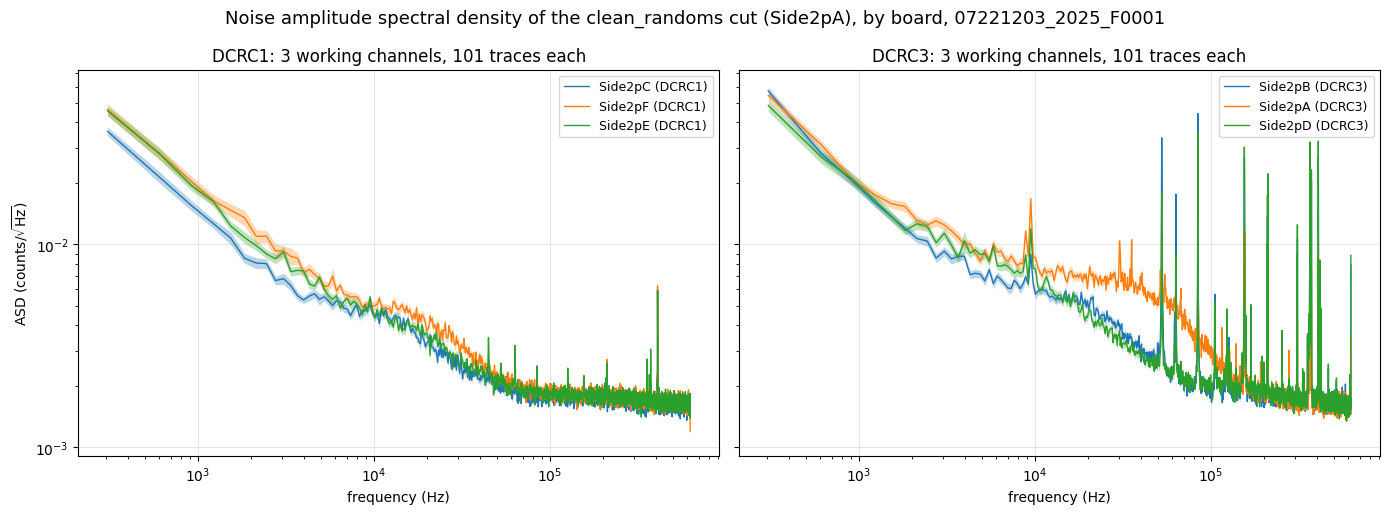

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
for ax, board in zip(axes, ("DCRC1", "DCRC3")):
    keys = [k for k in working if pch.channel_info(*k).dcrc == board]
    for i, key in enumerate(keys):
        mean, sem = asd_of(psd[key])
        colour = f"C{i}"
        ax.fill_between(freqs[1:], (mean - sem)[1:], (mean + sem)[1:], color=colour, alpha=0.3, linewidth=0)
        ax.loglog(freqs[1:], mean[1:], linewidth=1.0, color=colour, label=short_label(*key))
    ax.set_title(f"{board}: {len(keys)} working channels, {int(clean_randoms.sum())} traces each")
    ax.set_xlabel("frequency (Hz)")
    ax.grid(True, which="major", alpha=0.3)
    ax.legend(fontsize=9)
axes[0].set_ylabel("ASD (counts/$\\sqrt{\\mathrm{Hz}}$)")
fig.suptitle(f"Noise amplitude spectral density of the clean_randoms cut (Side2pA), by board, {DUMP}", fontsize=13)
fig.tight_layout()
plt.savefig(f"figures/psd-clean-randoms-by-board-{DUMP}.png", dpi=110)
plt.show()

## 5. The spectrum of every channel, one tile each

The same spectra as 12 tiles (rows are the boards DCRC1, DCRC3, DCRC4 and columns the four inputs of each board), all on the same axes, with the ±1 standard error band on the amplitude spectral density as above. An input that is not a sensor (the NaI trigger input or an unconnected input) has an empty tile.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\1476410113.py:5: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


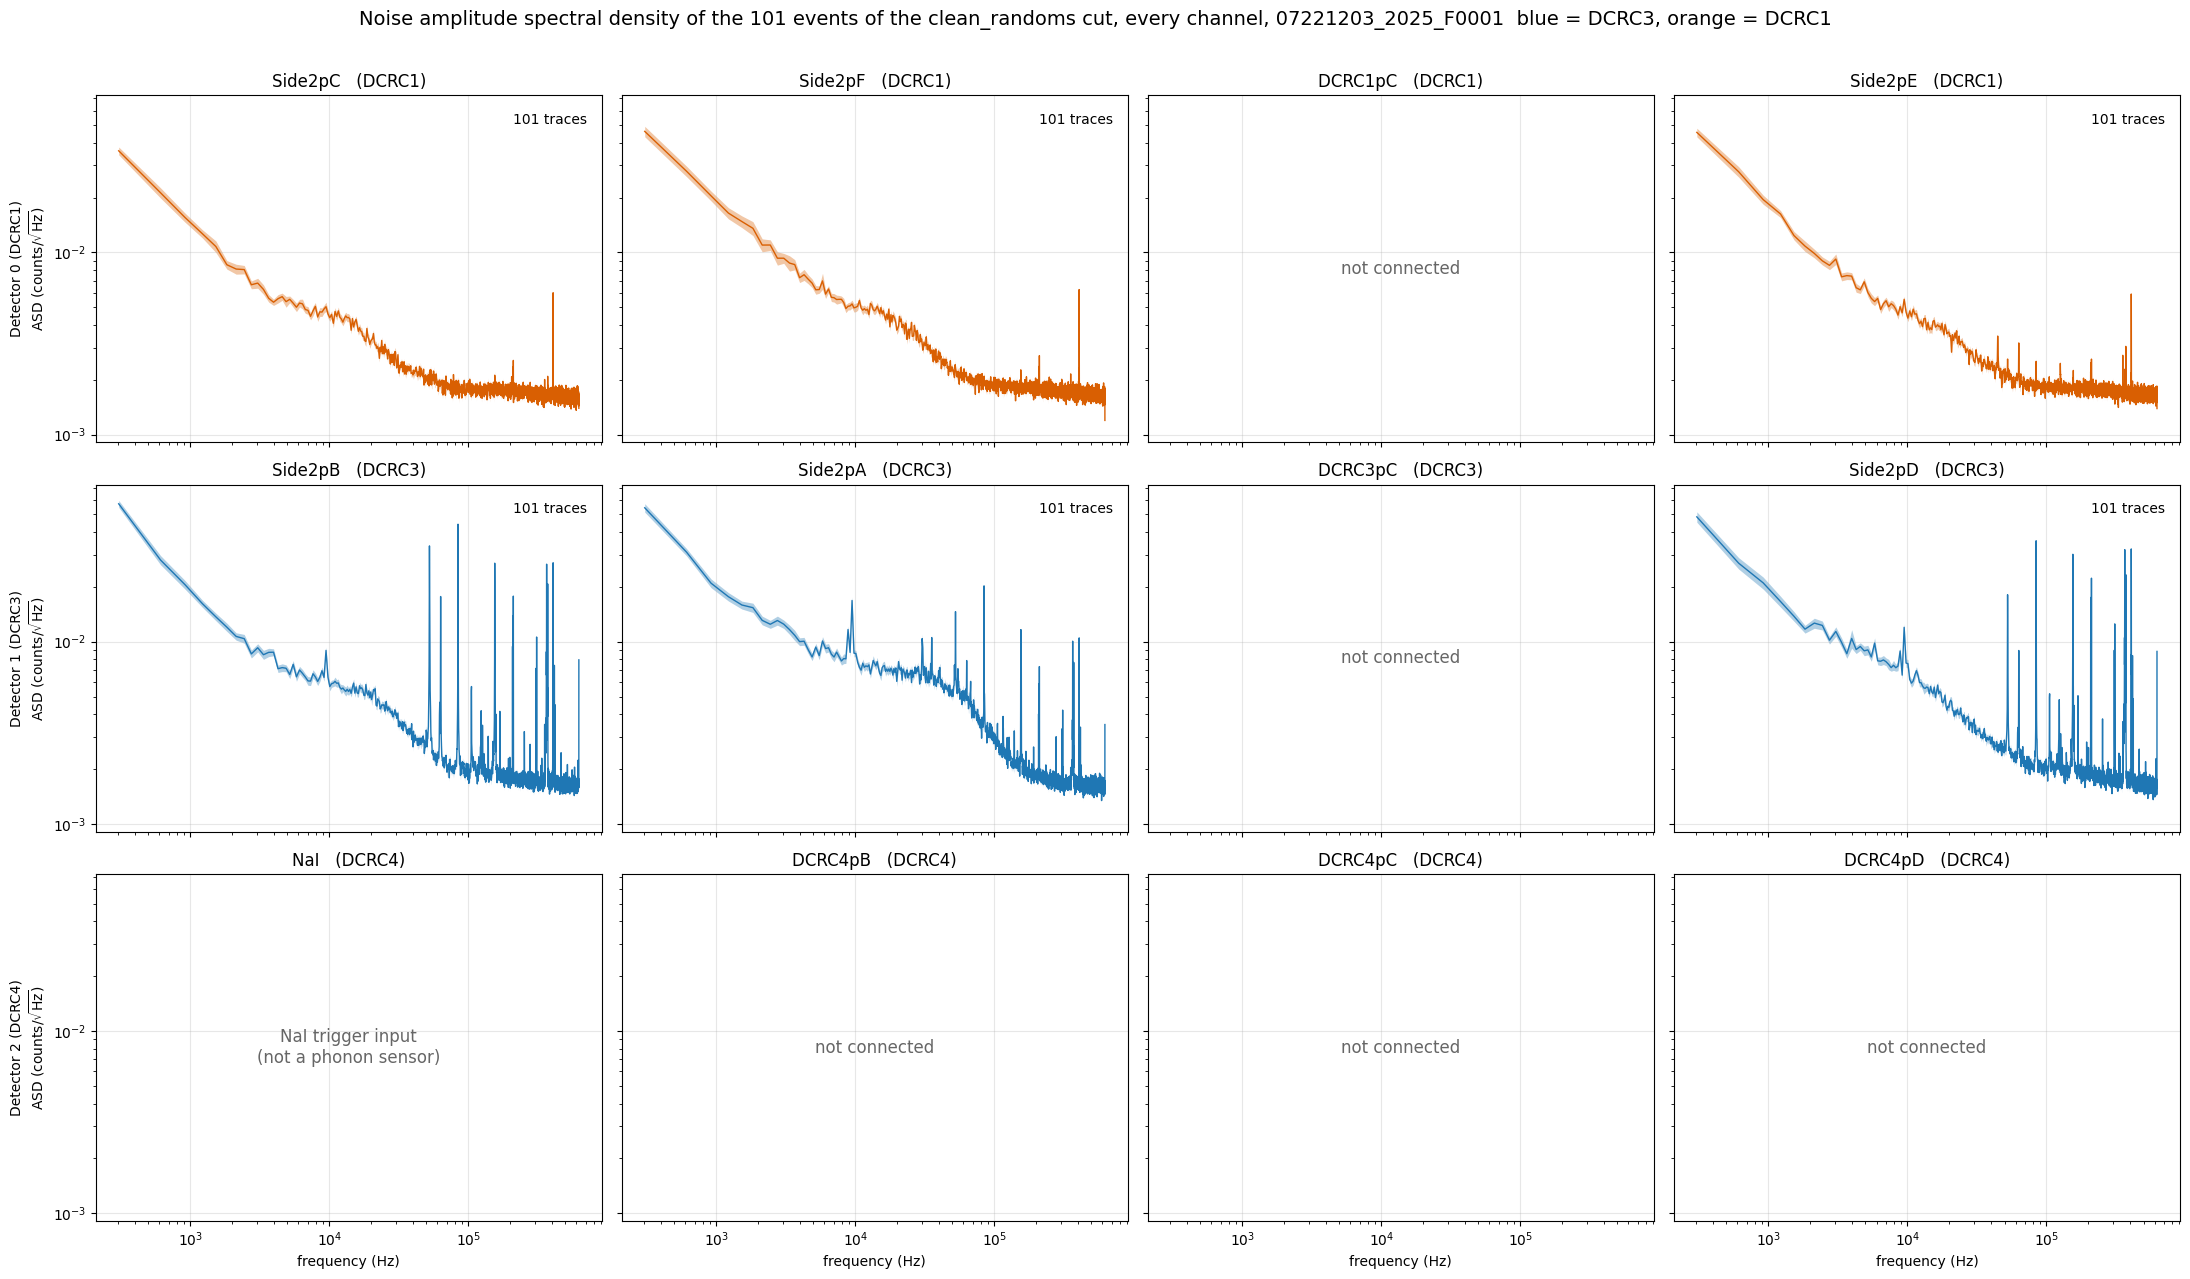

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(22, 13), sharex=True, sharey=True)
for key in KEYS:
    det, ch = key
    ax = axes[det, ch]
    c = pch.channel_info(det, ch)
    ax.set_title(f"{c.name}   ({c.dcrc})", fontsize=12)
    if key not in working:
        ax.text(0.5, 0.5, inactive_text(c), transform=ax.transAxes,
                ha="center", va="center", color="0.4", fontsize=12)
    else:
        mean, sem = asd_of(psd[key])
        ax.fill_between(freqs[1:], (mean - sem)[1:], (mean + sem)[1:], color=BOARD_COLOUR[c.dcrc], alpha=0.35, linewidth=0)
        ax.plot(freqs[1:], mean[1:], color=BOARD_COLOUR[c.dcrc], linewidth=1.0)
        ax.text(0.97, 0.95, f"{psd[key].shape[0]} traces", transform=ax.transAxes, ha="right", va="top", fontsize=10)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(True, which="major", alpha=0.3)
    if ch == 0:
        ax.set_ylabel(f"Detector {det} ({c.dcrc})" + chr(10) + "ASD (counts/$\\sqrt{\\mathrm{Hz}}$)")
    if det == 2:
        ax.set_xlabel("frequency (Hz)")
fig.suptitle(f"Noise amplitude spectral density of the {int(clean_randoms.sum())} events of the clean_randoms cut, every channel, {DUMP}"
             "  blue = DCRC3, orange = DCRC1", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(f"figures/psd-clean-randoms-tiles-{DUMP}.png", dpi=110)
plt.show()

## 6. Does it differ from the strictest cut?

The strictest cut keeps a random only if it is quiet in every working channel, which gives 34 events (Appendix A of the note). The 34 are all among the 101. For each channel, the ratio of the amplitude spectral density from the 101 events to the one from the 31, taken in the same three bands, shows how much the extra 67 events change the spectrum.

In [7]:
# the quiet-noise cut of every working channel, as in the noise notebook
quiet = {}
for key in working:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    with np.errstate(all="ignore"):
        quiet[key] = pc.excursion_band(p, config_500) & (np.log10(pq.bstd(p, config_500)) < 0.5)
is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
strict = is_random.copy()
for key in working:
    strict &= quiet[key]
print(f"the strictest cut keeps {strict.sum()} events; all of them are in clean_randoms: {bool(np.all(clean_randoms[strict]))}")
print()
in_strict = strict[clean_randoms]                         # which of the 101 are also in the strictest cut
print(f"{'channel':<20}" + "".join(f"{name:>13}" for name, _, _ in bands))
for key in working:
    all_mean = psd[key].mean(axis=0)
    strict_mean = psd[key][in_strict].mean(axis=0)
    ratios = [np.sqrt(all_mean[(freqs >= lo) & (freqs < hi)].mean() / strict_mean[(freqs >= lo) & (freqs < hi)].mean()) for _, lo, hi in bands]
    print(f"{short_label(*key):<20}" + "".join(f"{r:>13.2f}" for r in ratios))

the strictest cut keeps 34 events; all of them are in clean_randoms: True

channel                  1-10 kHz   10-100 kHz     >100 kHz
Side2pC (DCRC1)              1.11         1.01         1.00
Side2pF (DCRC1)              1.21         1.01         1.01
Side2pE (DCRC1)              1.12         0.99         1.00
Side2pB (DCRC3)              1.03         0.99         0.99
Side2pA (DCRC3)              0.98         0.98         1.00
Side2pD (DCRC3)              1.07         1.00         1.00


C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3429266805.py:7: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\3152283369.py:34: UserWarning: channel_info is ma

### 6.1 What the spectra show (this dump only)

- **The cut gives 101 traces in every one of the 6 working channels**, and the normalisation is right: for `Side2pC` the integral of the PSD over frequency (4.580 counts²) equals the mean square of its traces (4.580 counts²). The amplitude spectral density is the square root of that PSD.
- **All spectra fall steeply and then go flat.** Above 100 kHz the amplitude is the same, 1.70e-3 to 1.74e-3 counts/√Hz, in the three DCRC1 channels `Side2pC`, `Side2pF` and `Side2pE`, and higher in the DCRC3 channels `Side2pA` (1.98e-3), `Side2pB` (2.64e-3) and `Side2pD` (2.93e-3), where narrow lines raise the mean. Between 1 and 10 kHz it is 6.29e-3 to 1.10e-2 in the six channels.
- **Narrow lines differ by board.** The three DCRC3 channels (`Side2pB`, `Side2pA`, `Side2pD`) have many narrow lines at the high frequencies. The DCRC1 channels have one line near 400 kHz and a few small ones in `Side2pE`.
- **The NaI trigger input is not in this notebook.** An earlier version counted DCRC4 pA (then called `Side2pB`) as a seventh working channel; its flat spectrum, much lower than the others below 10 kHz, was not a phonon noise spectrum, because the input is the one that reads the trigger signal of the NaI array, not a sensor.
- **The uncertainty on the mean is about 5% of the amplitude in every channel**, 0.049 to 0.050 (the standard error of the mean PSD, 0.098 to 0.099 of its value, carried to the square root, which halves it). The spectra of single traces scatter much more, because each bin of a single trace's PSD is exponentially distributed; the mean over the traces is known to a few per cent.
- **The extra 67 events change the mean amplitude little above 10 kHz.** Compared with the 34 events of the strictest cut, the ratio of the amplitude spectral density is between 0.98 and 1.01 in the bands above 10 kHz, and between 0.98 and 1.21 (1.03 to 1.21 in five channels) between 1 and 10 kHz, where the 34 events have less low-frequency power. The 101 events give essentially the same spectra above 10 kHz, from about three times as many traces.

## 7. Save the spectra

The amplitude spectral density of every working channel (and the PSD it comes from), their standard errors and the frequency axis go into one small HDF5 file next to this notebook, together with the event numbers of the cut and the settings that made them, so that the optimal filter (or anyone else) can read them without re-running anything. The per-trace spectra are not saved; they can be recomputed from the event list.

Layout of `psd-clean-randoms-<dump>.h5`:

| Where | What |
|---|---|
| attributes of the file | the dump, the cut, the conventions, the units, the sample period and the number of samples per trace |
| `/frequency_hz` | the frequency bins (Hz), shared by all channels |
| `/event_numbers` | the event numbers of the 101 events of the cut (event numbers restart in every dump) |
| `/channels/<name>/asd_mean`, `asd_sem` | the amplitude spectral density (counts/$\sqrt{\mathrm{Hz}}$, one-sided) and its standard error, with the attributes `detector`, `channel`, `side` (always 2), `dcrc`, `board_input`, `hv_output` |
| `/channels/<name>/psd_mean`, `psd_sem` | the one-sided PSD (counts$^2$/Hz) it is the square root of, and its standard error |

The six inputs that are not sensors have no group. In Golwala's convention (two-sided, thesis appendix B) the PSD is J = S/2 and the amplitude is $\sqrt{J} = \mathrm{ASD}/\sqrt{2}$.

In [8]:
import h5py

OUT = Path(f"psd-clean-randoms-{DUMP}.h5")
with h5py.File(OUT, "w") as f:
    f.attrs["dump"] = DUMP
    f.attrs["cut"] = "clean_randoms: pc.randoms and pc.excursion_band(Tight, 500-sample pretrigger) and log10(bstd) < 0.5, on Side2pA (detector 1, channel 1)"
    f.attrs["cut_channel"] = pch.channel_name(*CLEAN_KEY)
    f.attrs["psd_convention"] = "one-sided: S = (2 dt / N) * mean over traces of |X[k]|^2, no factor 2 at DC and Nyquist; baseline-subtracted, glitch samples dropped"
    f.attrs["asd_convention"] = "asd = sqrt(S), one-sided; asd_sem = psd_sem / (2 asd). Golwala (thesis appendix B) uses the two-sided J = S/2, so sqrt(J) = asd / sqrt(2)"
    f.attrs["units"] = "psd: counts^2 / Hz; asd: counts / sqrt(Hz)"
    f.attrs["sample_period_s"] = config_500.sample_period_s
    f.attrs["samples_per_trace"] = n_samples
    f.attrs["pretrigger_samples"] = config_500.pretrigger_samples
    f.attrs["glitch_samples"] = config_500.glitch_samples
    f.attrs["n_events"] = int(clean_randoms.sum())
    f.attrs["note"] = "channel names are provisional (pulse_channels, Side-2 readout: six sensors, all Side 2); trigger labels assume the swap of Note 2a"
    f.create_dataset("frequency_hz", data=freqs)
    f.create_dataset("event_numbers", data=event_numbers[clean_randoms])
    grp = f.create_group("channels")
    for key in working:
        info_ch = pch.channel_info(*key)
        g = grp.create_group(info_ch.name)
        g.attrs.update(detector=key[0], channel=key[1], side=info_ch.side, dcrc=info_ch.dcrc, board_input=info_ch.board_input, hv_output=info_ch.hv_output)
        asd, asd_sem = asd_of(psd[key])
        g.create_dataset("asd_mean", data=asd)
        g.create_dataset("asd_sem", data=asd_sem)
        g.create_dataset("psd_mean", data=psd[key].mean(axis=0))
        g.create_dataset("psd_sem", data=psd[key].std(axis=0, ddof=1) / np.sqrt(psd[key].shape[0]))

# read it back and check it
with h5py.File(OUT, "r") as f:
    assert np.array_equal(f["frequency_hz"][:], freqs)
    assert np.array_equal(f["event_numbers"][:], event_numbers[clean_randoms])
    for key in working:
        name = pch.channel_info(*key).name
        assert np.allclose(f["channels"][name]["psd_mean"][:], psd[key].mean(axis=0))
        assert np.allclose(f["channels"][name]["asd_mean"][:] ** 2, f["channels"][name]["psd_mean"][:])
    print(f"{OUT} written and read back: {len(f['channels'])} channels, {f['frequency_hz'].shape[0]} frequency bins, "
          f"{f['event_numbers'].shape[0]} events, {OUT.stat().st_size / 1e3:.0f} kB")

psd-clean-randoms-07221203_2025_F0001.h5 written and read back: 6 channels, 2044 frequency bins, 101 events, 435 kB


C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\2034719087.py:7: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  f.attrs["cut_channel"] = pch.channel_name(*CLEAN_KEY)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\2034719087.py:21: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  info_ch = pch.channel_info(*key)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_8196\2034719087.py:35: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against 

## Next steps

- Read the spectra and the table above and write down what they show.
- Repeat for another dump, and check that the cut keeps a similar number of events.